# 🤖 MACHINE LEARNING — ANALISIS DATA ONLINE RETAIL

## 👥 Identitas Kelompok

| 👤 Nama Kelompok      | 🆔 NIM        |
| --------------------- | ------------- |
| Dharma Putranto       | 241011402573  |
| Ghauri Zaki Al Fatih  | 241011400652  |
| M. Nizar Citra Wijaya | 2410111402192 |

🏫 **Kelas:** 04TPLP16
💻 **Program Studi:** Teknik Informatika

---

## 📌  IMPORT LIBRARY

Pada tahap ini dilakukan proses import library Python yang digunakan untuk pengolahan data, analisis data, visualisasi, preprocessing, pembuatan model **Machine Learning**, serta evaluasi model.

🚀 Library yang digunakan meliputi:

* 🐼 **Pandas** — pengolahan dan manipulasi data
* 🔢 **NumPy** — operasi numerik
* 📊 **Matplotlib** — visualisasi data
* 🎨 **Seaborn** — visualisasi statistik
* 🤖 **Scikit-Learn** — preprocessing, pemodelan, dan evaluasi Machine Learning


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Library berhasil diimport!")

Library berhasil diimport!


## 👀  MENAMPILKAN DATA AWAL

Pada tahap ini dilakukan pemeriksaan terhadap beberapa data pertama dari dataset.

🔎 Dengan menampilkan data awal, kita dapat mengetahui bentuk data, nama kolom, serta gambaran informasi yang terdapat dalam dataset.

🎯 **Tujuan:** Memahami struktur awal dataset sebelum dilakukan proses pembersihan dan analisis lebih lanjut.

In [2]:
# Membaca dataset CSV
df = pd.read_csv("Online Retail.csv")

# Menampilkan 5 data pertama
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 📂 Membaca Dataset

Pada tahap ini, dataset **Online Retail** yang telah disimpan dalam format CSV akan dibaca menggunakan library **Pandas**. Dataset digunakan sebagai sumber data utama dalam proses analisis dan penerapan algoritma Machine Learning.

Setelah dataset berhasil dibaca, dilakukan pengecekan awal berupa jumlah baris dan kolom untuk mengetahui ukuran dataset yang akan dianalisis. 📊


In [3]:
# Membaca Dataset
df = pd.read_csv("Online Retail.csv")

# Menampilkan informasi singkat dataset
print("Dataset berhasil dibaca!")
print("Jumlah baris dan kolom:", df.shape)

Dataset berhasil dibaca!
Jumlah baris dan kolom: (541909, 8)


## 1️⃣ Missing Value

Missing Value adalah kondisi ketika terdapat data yang kosong pada suatu kolom dalam dataset. Pemeriksaan dilakukan untuk mengetahui apakah terdapat data kosong yang dapat memengaruhi proses analisis dan pemodelan Machine Learning.

Pada tahap ini, jumlah Missing Value pada setiap kolom akan diperiksa menggunakan fungsi `isnull().sum()`.


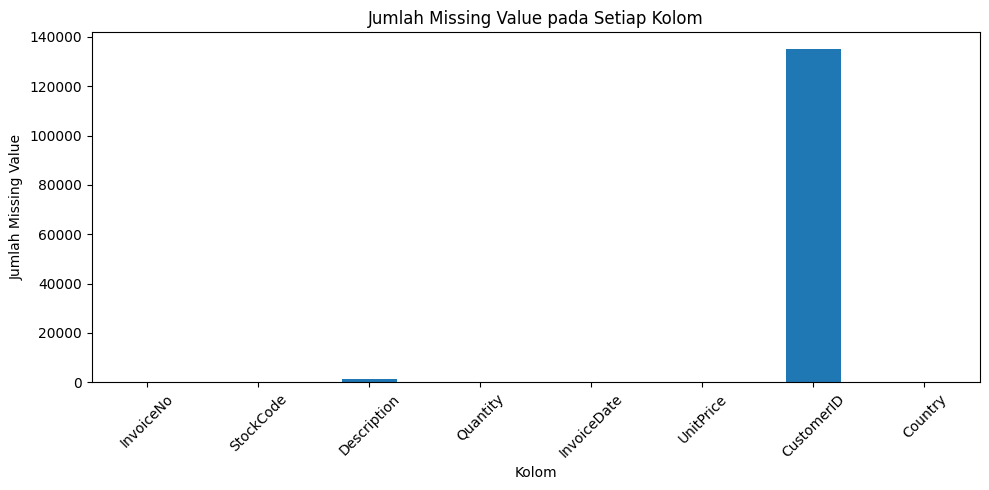

In [4]:
import matplotlib.pyplot as plt

# Membuat grafik missing value
missing_values = df.isnull().sum()

plt.figure(figsize=(10, 5))
missing_values.plot(kind='bar')

plt.title("Jumlah Missing Value pada Setiap Kolom")
plt.xlabel("Kolom")
plt.ylabel("Jumlah Missing Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2️⃣ Data Duplikat

Data duplikat adalah data yang memiliki isi yang sama dengan data lainnya. Data duplikat perlu diperiksa karena dapat memengaruhi hasil analisis dan menyebabkan perhitungan menjadi kurang akurat.

Pada tahap ini dilakukan pengecekan jumlah data duplikat pada dataset. Jika ditemukan data duplikat, maka data tersebut akan dihapus agar dataset menjadi lebih bersih dan siap digunakan untuk proses analisis selanjutnya.


In [5]:
# Mengecek jumlah data duplikat
jumlah_duplikat = df.duplicated().sum()

print("Jumlah data duplikat:", jumlah_duplikat)

# Menghapus data duplikat
df = df.drop_duplicates()

print("Jumlah data setelah menghapus duplikat:", len(df))

# Mengecek kembali
print("Jumlah data duplikat setelah penanganan:", df.duplicated().sum())

Jumlah data duplikat: 5268
Jumlah data setelah menghapus duplikat: 536641
Jumlah data duplikat setelah penanganan: 0


## 3️⃣ Data Tidak Konsisten

Data tidak konsisten adalah kondisi ketika nilai dalam dataset memiliki format atau penulisan yang berbeda, padahal menunjukkan informasi yang sama. Ketidakkonsistenan dapat mengganggu proses pengolahan dan analisis data.

Pada tahap ini dilakukan pemeriksaan terhadap nilai pada kolom bertipe kategori dan teks. Data akan diperiksa untuk mengetahui adanya perbedaan penulisan seperti penggunaan huruf besar dan kecil atau spasi yang tidak diperlukan.


In [6]:
# Mengecek nilai unik pada kolom bertipe object
for kolom in df.select_dtypes(include='object').columns:
    print(f"\nNilai unik pada kolom {kolom}:")
    print(df[kolom].unique()[:20])

# Membersihkan spasi berlebih pada kolom teks
for kolom in df.select_dtypes(include='object').columns:
    df[kolom] = df[kolom].str.strip()

print("\nData teks setelah dibersihkan dari spasi berlebih:")
print(df.head())


Nilai unik pada kolom InvoiceNo:
<StringArray>
[ '536365',  '536366',  '536367',  '536368',  '536369',  '536370',  '536371',
  '536372',  '536373',  '536374',  '536375',  '536376',  '536377',  '536378',
  '536380',  '536381', 'C536379',  '536382', 'C536383',  '536384']
Length: 20, dtype: str

Nilai unik pada kolom StockCode:
<StringArray>
['85123A',  '71053', '84406B', '84029G', '84029E',  '22752',  '21730',
  '22633',  '22632',  '84879',  '22745',  '22748',  '22749',  '22310',
  '84969',  '22623',  '22622',  '21754',  '21755',  '21777']
Length: 20, dtype: str

Nilai unik pada kolom Description:


C:\Users\mrads\AppData\Local\Temp\ipykernel_6896\793184756.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for kolom in df.select_dtypes(include='object').columns:


<StringArray>
[ 'WHITE HANGING HEART T-LIGHT HOLDER',                 'WHITE METAL LANTERN',
      'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE',
      'RED WOOLLY HOTTIE WHITE HEART.',        'SET 7 BABUSHKA NESTING BOXES',
   'GLASS STAR FROSTED T-LIGHT HOLDER',              'HAND WARMER UNION JACK',
           'HAND WARMER RED POLKA DOT',       'ASSORTED COLOUR BIRD ORNAMENT',
          'POPPY'S PLAYHOUSE BEDROOM ',           'POPPY'S PLAYHOUSE KITCHEN',
   'FELTCRAFT PRINCESS CHARLOTTE DOLL',             'IVORY KNITTED MUG COSY ',
  'BOX OF 6 ASSORTED COLOUR TEASPOONS',       'BOX OF VINTAGE JIGSAW BLOCKS ',
      'BOX OF VINTAGE ALPHABET BLOCKS',            'HOME BUILDING BLOCK WORD',
            'LOVE BUILDING BLOCK WORD',         'RECIPE BOX WITH METAL HEART']
Length: 20, dtype: str

Nilai unik pada kolom InvoiceDate:
<StringArray>
['12/1/2010 8:26', '12/1/2010 8:28', '12/1/2010 8:34', '12/1/2010 8:35',
 '12/1/2010 8:45', '12/1/2010 9:00', '12/1/2010 9:

C:\Users\mrads\AppData\Local\Temp\ipykernel_6896\793184756.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for kolom in df.select_dtypes(include='object').columns:



Data teks setelah dibersihkan dari spasi berlebih:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  


## 4️⃣ Data Tidak Valid

Data tidak valid adalah data yang memiliki nilai yang tidak sesuai dengan aturan atau konteks data. Pada dataset transaksi, contoh data tidak valid dapat berupa jumlah barang atau harga yang bernilai nol maupun negatif.

Pada tahap ini dilakukan pemeriksaan terhadap kolom `Quantity` dan `UnitPrice`. Data dengan nilai yang tidak valid akan diidentifikasi dan ditangani agar tidak mengganggu proses analisis.


In [7]:
# Mengecek jumlah Quantity yang tidak valid
print("Quantity <= 0:", (df['Quantity'] <= 0).sum())

# Mengecek jumlah UnitPrice yang tidak valid
print("UnitPrice <= 0:", (df['UnitPrice'] <= 0).sum())

# Menghapus data dengan Quantity <= 0
df = df[df['Quantity'] > 0]

# Menghapus data dengan UnitPrice <= 0
df = df[df['UnitPrice'] > 0]

# Mengecek kembali
print("\nSetelah penanganan:")
print("Quantity <= 0:", (df['Quantity'] <= 0).sum())
print("UnitPrice <= 0:", (df['UnitPrice'] <= 0).sum())

print("\nJumlah data setelah penanganan:", len(df))

Quantity <= 0: 10587
UnitPrice <= 0: 2512

Setelah penanganan:
Quantity <= 0: 0
UnitPrice <= 0: 0

Jumlah data setelah penanganan: 524878


## 5️⃣ Outlier

Outlier adalah data yang memiliki nilai jauh berbeda dibandingkan dengan sebagian besar data lainnya. Outlier perlu diperiksa karena dapat memengaruhi hasil perhitungan statistik dan analisis.

Pada tahap ini, outlier akan diperiksa pada kolom numerik menggunakan metode **Interquartile Range (IQR)**. Jika ditemukan nilai yang berada di luar batas IQR, data tersebut akan diidentifikasi dan ditangani.


In [8]:
# Menentukan kolom yang akan diperiksa
kolom_numerik = ['Quantity', 'UnitPrice']

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    print(f"\nKolom: {kolom}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Batas bawah:", batas_bawah)
    print("Batas atas:", batas_atas)
    print("Jumlah outlier:", jumlah_outlier)


Kolom: Quantity
Q1: 1.0
Q3: 11.0
IQR: 10.0
Batas bawah: -14.0
Batas atas: 26.0
Jumlah outlier: 27111

Kolom: UnitPrice
Q1: 1.25
Q3: 4.13
IQR: 2.88
Batas bawah: -3.0700000000000003
Batas atas: 8.45
Jumlah outlier: 37827


### Penanganan Outlier

Outlier yang ditemukan akan ditangani menggunakan metode **IQR**. Data yang berada di bawah batas bawah atau di atas batas atas akan dikeluarkan dari dataset. Dengan demikian, data yang digunakan pada tahap berikutnya berada dalam rentang yang lebih wajar.


In [9]:
# Menyimpan jumlah data sebelum penanganan
jumlah_sebelum = len(df)

# Menentukan batas IQR untuk Quantity
Q1_quantity = df['Quantity'].quantile(0.25)
Q3_quantity = df['Quantity'].quantile(0.75)
IQR_quantity = Q3_quantity - Q1_quantity

batas_bawah_quantity = Q1_quantity - 1.5 * IQR_quantity
batas_atas_quantity = Q3_quantity + 1.5 * IQR_quantity

# Menentukan batas IQR untuk UnitPrice
Q1_price = df['UnitPrice'].quantile(0.25)
Q3_price = df['UnitPrice'].quantile(0.75)
IQR_price = Q3_price - Q1_price

batas_bawah_price = Q1_price - 1.5 * IQR_price
batas_atas_price = Q3_price + 1.5 * IQR_price

# Menghapus data yang berada di luar batas IQR
df = df[
    (df['Quantity'] >= batas_bawah_quantity) &
    (df['Quantity'] <= batas_atas_quantity) &
    (df['UnitPrice'] >= batas_bawah_price) &
    (df['UnitPrice'] <= batas_atas_price)
]

# Menampilkan hasil
jumlah_sesudah = len(df)

print("Jumlah data sebelum penanganan:", jumlah_sebelum)
print("Jumlah data sesudah penanganan:", jumlah_sesudah)
print("Jumlah data yang dihapus:", jumlah_sebelum - jumlah_sesudah)

Jumlah data sebelum penanganan: 524878
Jumlah data sesudah penanganan: 460251
Jumlah data yang dihapus: 64627


## 6️⃣ Format Data

Format data yang tidak sesuai dapat menyulitkan proses pengolahan dan analisis. Salah satu contoh pada dataset ini adalah kolom `InvoiceDate` yang masih berupa teks.

Pada tahap ini, kolom `InvoiceDate` akan dikonversi menjadi format tanggal dan waktu (`datetime`) agar dapat digunakan untuk analisis berdasarkan tanggal maupun waktu transaksi.


In [10]:
# Mengubah InvoiceDate menjadi format datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Mengecek tipe data setelah dikonversi
print("Tipe data InvoiceDate:")
print(df['InvoiceDate'].dtype)

# Menampilkan beberapa data
print("\nContoh data setelah dikonversi:")
print(df[['InvoiceNo', 'InvoiceDate']].head())

Tipe data InvoiceDate:
datetime64[us]

Contoh data setelah dikonversi:
  InvoiceNo         InvoiceDate
0    536365 2010-12-01 08:26:00
1    536365 2010-12-01 08:26:00
2    536365 2010-12-01 08:26:00
3    536365 2010-12-01 08:26:00
4    536365 2010-12-01 08:26:00


## 7️⃣ Encoding Data

Encoding adalah proses mengubah data kategorikal menjadi bentuk numerik agar dapat diproses oleh algoritma Machine Learning. Pada dataset Online Retail, kolom `Country` merupakan data kategorikal yang berisi nama negara.

Pada tahap ini, kolom `Country` akan diubah menjadi data numerik menggunakan **Label Encoding**. Setiap negara akan diberikan nilai angka yang berbeda.


In [11]:
from sklearn.preprocessing import LabelEncoder

# Membuat objek LabelEncoder
encoder = LabelEncoder()

# Mengubah Country menjadi data numerik
df['Country_Encoded'] = encoder.fit_transform(df['Country'])

# Menampilkan hasil encoding
print("Contoh data sebelum dan sesudah encoding:")
print(df[['Country', 'Country_Encoded']].head(10))

# Menampilkan jumlah kategori negara
print("\nJumlah negara:", df['Country'].nunique())

Contoh data sebelum dan sesudah encoding:
           Country  Country_Encoded
0   United Kingdom               36
1   United Kingdom               36
2   United Kingdom               36
3   United Kingdom               36
4   United Kingdom               36
5   United Kingdom               36
6   United Kingdom               36
7   United Kingdom               36
8   United Kingdom               36
10  United Kingdom               36

Jumlah negara: 38


### Grafik Jumlah Transaksi Berdasarkan Negara

Grafik berikut menampilkan 10 negara dengan jumlah transaksi terbanyak pada dataset Online Retail. Grafik ini digunakan untuk melihat distribusi transaksi berdasarkan negara.


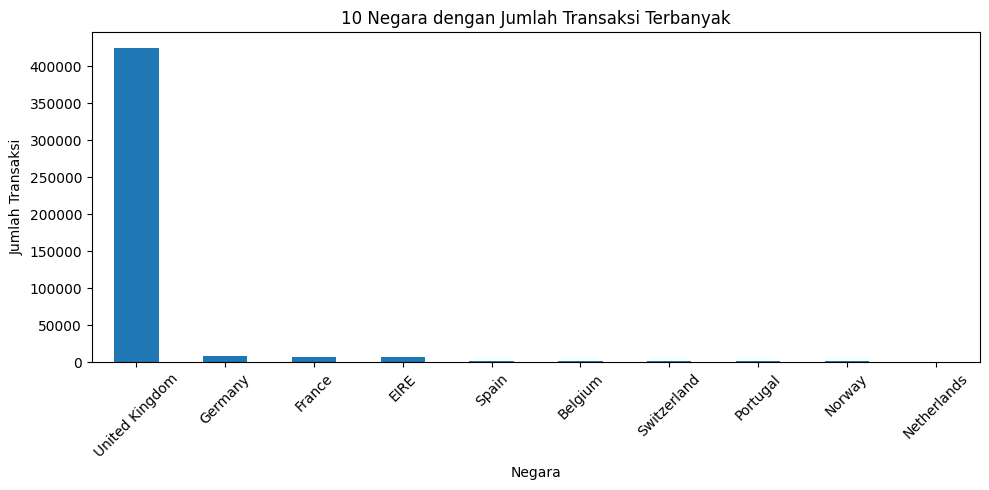

In [12]:
import matplotlib.pyplot as plt

# Menghitung 10 negara dengan jumlah transaksi terbanyak
top_country = df['Country'].value_counts().head(10)

# Membuat grafik
plt.figure(figsize=(10, 5))
top_country.plot(kind='bar')

plt.title('10 Negara dengan Jumlah Transaksi Terbanyak')
plt.xlabel('Negara')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8️⃣ Normalisasi Data

Normalisasi adalah proses mengubah nilai data ke dalam skala tertentu agar perbedaan rentang antarfitur tidak terlalu besar.

Pada dataset Online Retail, kolom `Quantity` dan `UnitPrice` memiliki rentang nilai yang berbeda. Oleh karena itu, dilakukan normalisasi menggunakan metode **Min-Max Scaling** dengan rentang nilai 0 sampai 1.

Hasil normalisasi akan digunakan agar data numerik memiliki skala yang lebih seragam dan dapat diproses dengan lebih baik oleh algoritma Machine Learning.


In [13]:
from sklearn.preprocessing import MinMaxScaler

# Kolom numerik yang akan dinormalisasi
fitur_numerik = ['Quantity', 'UnitPrice']

# Membuat objek MinMaxScaler
scaler = MinMaxScaler()

# Membuat salinan data
df_normalisasi = df.copy()

# Melakukan normalisasi
df_normalisasi[fitur_numerik] = scaler.fit_transform(df[fitur_numerik])

# Menampilkan hasil normalisasi
print("Data setelah normalisasi:")
print(df_normalisasi[fitur_numerik].head())

# Mengecek nilai minimum dan maksimum
print("\nNilai minimum:")
print(df_normalisasi[fitur_numerik].min())

print("\nNilai maksimum:")
print(df_normalisasi[fitur_numerik].max())

Data setelah normalisasi:
   Quantity  UnitPrice
0      0.20   0.306039
1      0.20   0.406892
2      0.28   0.330052
3      0.20   0.406892
4      0.20   0.406892

Nilai minimum:
Quantity     0.0
UnitPrice    0.0
dtype: float64

Nilai maksimum:
Quantity     1.0
UnitPrice    1.0
dtype: float64


## 9️⃣ Feature Engineering

Feature Engineering adalah proses membuat fitur baru dari data yang sudah tersedia agar informasi dalam dataset dapat digunakan dengan lebih baik oleh algoritma Machine Learning.

Pada dataset Online Retail, fitur baru `TotalPrice` dibuat dengan mengalikan `Quantity` dan `UnitPrice`. Fitur ini menunjukkan total nilai dari setiap transaksi.

Selain membuat fitur baru, hasilnya akan divisualisasikan untuk melihat produk dengan nilai transaksi terbesar.


In [14]:
# Membuat fitur baru TotalPrice
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Menampilkan hasil
print("Contoh data setelah Feature Engineering:")
print(df[['Quantity', 'UnitPrice', 'TotalPrice']].head())

# Mengecek statistik TotalPrice
print("\nStatistik TotalPrice:")
print(df['TotalPrice'].describe())

Contoh data setelah Feature Engineering:
   Quantity  UnitPrice  TotalPrice
0         6       2.55       15.30
1         6       3.39       20.34
2         8       2.75       22.00
3         6       3.39       20.34
4         6       3.39       20.34

Statistik TotalPrice:
count    460251.000000
mean         11.729846
std          13.174559
min           0.001000
25%           3.300000
50%           8.250000
75%          15.900000
max         215.540000
Name: TotalPrice, dtype: float64


### Grafik Total Nilai Transaksi Berdasarkan Produk

Grafik berikut menampilkan 10 produk dengan total nilai transaksi terbesar. Visualisasi ini digunakan untuk melihat produk yang memberikan nilai transaksi paling besar pada dataset.


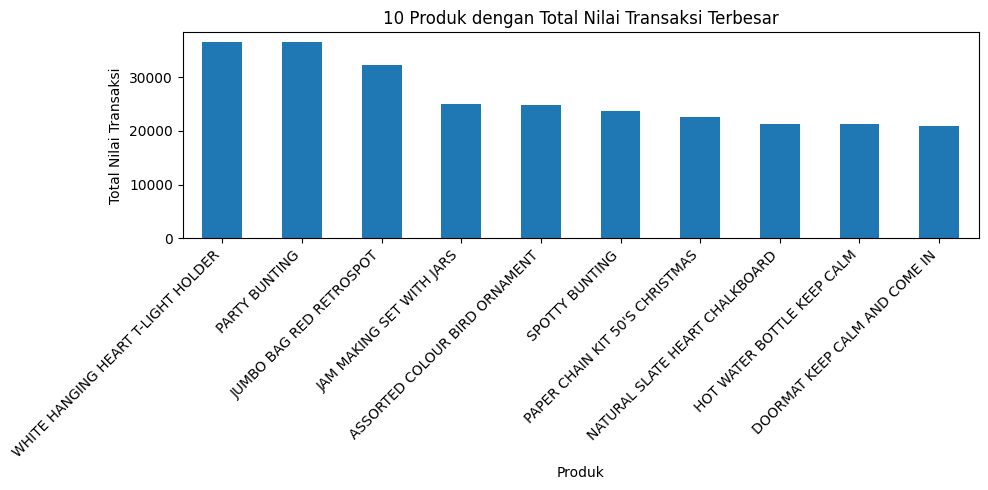

In [15]:
import matplotlib.pyplot as plt

# Menghitung total nilai transaksi setiap produk
top_produk = (
    df.groupby('Description')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Membuat grafik
plt.figure(figsize=(10, 5))
top_produk.plot(kind='bar')

plt.title('10 Produk dengan Total Nilai Transaksi Terbesar')
plt.xlabel('Produk')
plt.ylabel('Total Nilai Transaksi')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 🔟 Seleksi Fitur

Seleksi fitur adalah proses memilih fitur yang memiliki hubungan atau pengaruh terhadap data lainnya. Tahap ini dilakukan untuk mengetahui hubungan antarfitur numerik dalam dataset.

Pada tahap ini digunakan **Correlation Matrix** untuk melihat hubungan antarfitur numerik seperti `Quantity`, `UnitPrice`, dan `TotalPrice`. Hasil korelasi akan divisualisasikan menggunakan **heatmap**.


In [16]:
import matplotlib.pyplot as plt

# Memilih fitur numerik
fitur = df[['Quantity', 'UnitPrice', 'TotalPrice']]

# Menghitung korelasi
korelasi = fitur.corr()

# Menampilkan nilai korelasi
print("Matriks Korelasi:")
print(korelasi)

Matriks Korelasi:
            Quantity  UnitPrice  TotalPrice
Quantity    1.000000  -0.351540    0.531759
UnitPrice  -0.351540   1.000000    0.289093
TotalPrice  0.531759   0.289093    1.000000


### Heatmap Korelasi Antarfitur

Heatmap berikut menampilkan hubungan antarfitur numerik pada dataset. Nilai korelasi digunakan untuk melihat seberapa kuat hubungan antara satu fitur dengan fitur lainnya.


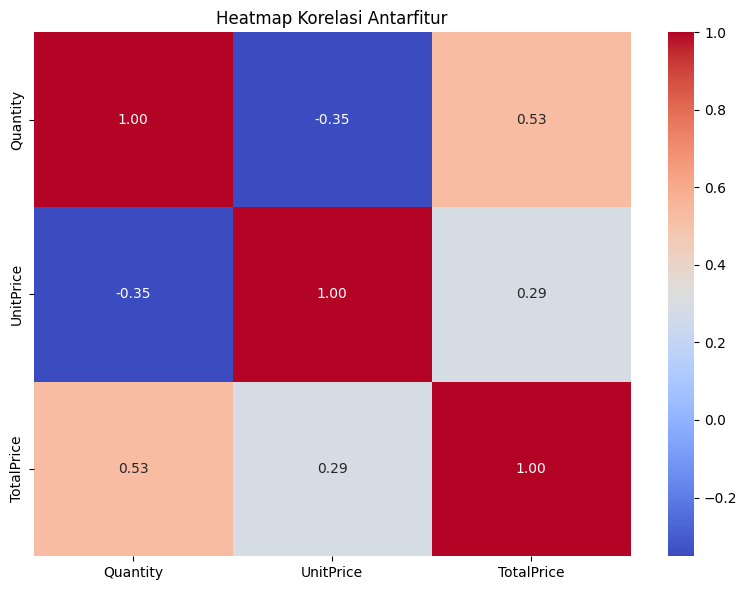

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Membuat heatmap korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Heatmap Korelasi Antarfitur')
plt.tight_layout()
plt.show()


## 1️⃣1️⃣ Penerapan Algoritma K-Means Clustering

K-Means Clustering adalah algoritma Machine Learning tanpa pengawasan (*unsupervised learning*) yang mengelompokkan data berdasarkan kemiripan karakteristik dan jarak terhadap pusat cluster. Pada penelitian ini, K-Means digunakan untuk mengelompokkan pelanggan berdasarkan pola transaksi menggunakan fitur Recency, Frequency, dan Monetary (RFM).



Jumlah pelanggan yang dianalisis: 4196


,Recency,Frequency,Monetary
CustomerID,,,
12347.0,2,7,3412.53
12348.0,249,3,90.20
12349.0,19,1,1197.15
12350.0,310,1,294.40
12352.0,36,7,1147.44


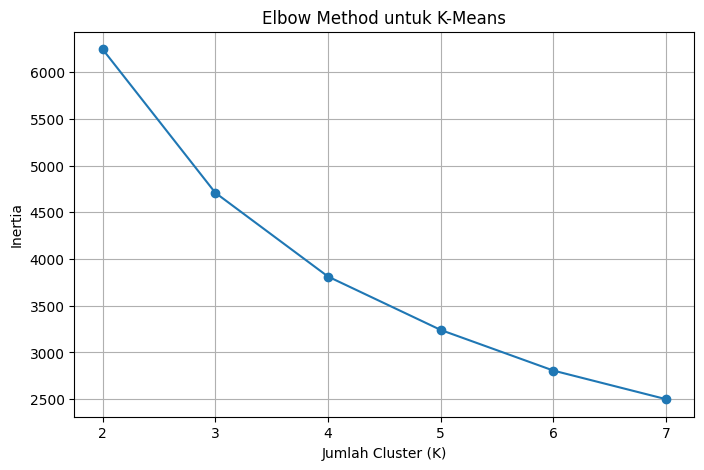

Jumlah pelanggan pada setiap cluster:
Cluster
0    1805
1     748
2    1643
Name: count, dtype: int64

Rata-rata RFM setiap cluster:


,Recency,Frequency,Monetary
Cluster,,,
0,167.18,1.32,252.63
1,14.80,12.24,3523.22
2,45.50,3.28,881.12


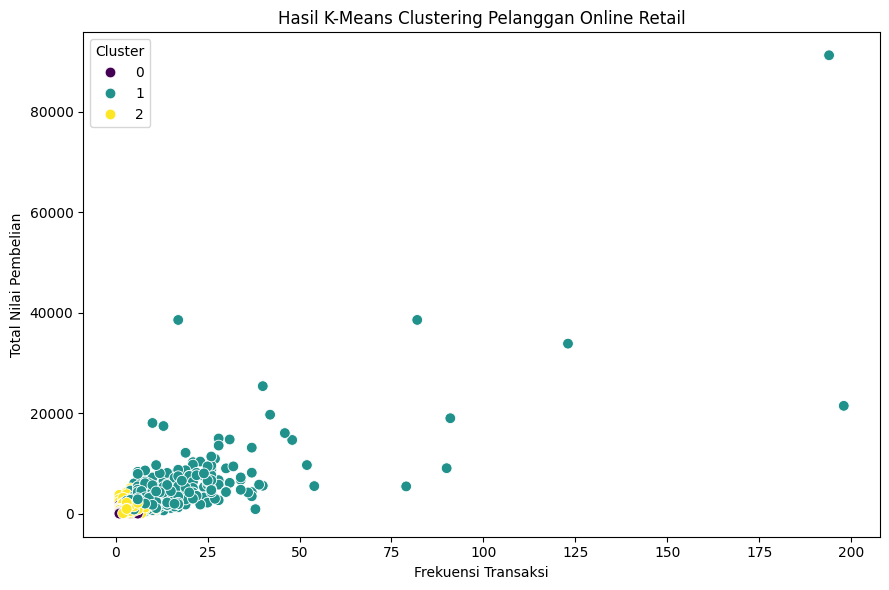

Silhouette Score: 0.3349


In [18]:

# =====================================================
# 11. PENERAPAN ALGORITMA K-MEANS CLUSTERING
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Menyiapkan data transaksi
data_cluster = df.copy()

# Pastikan tanggal transaksi bertipe datetime
data_cluster['InvoiceDate'] = pd.to_datetime(
    data_cluster['InvoiceDate'], errors='coerce'
)

# Menghapus data yang tidak memiliki ID pelanggan
data_cluster = data_cluster.dropna(subset=['CustomerID'])

# Menghapus transaksi batal dan data tidak valid
data_cluster = data_cluster[
    (~data_cluster['InvoiceNo'].astype(str).str.startswith('C')) &
    (data_cluster['Quantity'] > 0) &
    (data_cluster['UnitPrice'] > 0)
].copy()

# Menghitung total nilai transaksi
data_cluster['TotalPrice'] = (
    data_cluster['Quantity'] * data_cluster['UnitPrice']
)

# 2. Menghitung RFM pelanggan
tanggal_acuan = (
    data_cluster['InvoiceDate'].max()
    + pd.Timedelta(days=1)
)

rfm = data_cluster.groupby('CustomerID').agg(
    Recency=('InvoiceDate',
             lambda x: (tanggal_acuan - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
)

# Menghilangkan nilai yang tidak valid
rfm = rfm.replace([np.inf, -np.inf], np.nan).dropna()
rfm = rfm[(rfm > 0).all(axis=1)]

print("Jumlah pelanggan yang dianalisis:", len(rfm))
display(rfm.head())

# 3. Transformasi log untuk mengurangi kemencengan data
rfm_log = np.log1p(rfm)

# 4. Standardisasi data
scaler_rfm = StandardScaler()
rfm_scaled = scaler_rfm.fit_transform(rfm_log)

# 5. Elbow Method untuk memilih jumlah cluster
inertia = []
nilai_k = range(2, 8)

for k in nilai_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(rfm_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(nilai_k), inertia, marker='o')
plt.title('Elbow Method untuk K-Means')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(list(nilai_k))
plt.grid(True)
plt.show()

# 6. Melatih model K-Means
# Gunakan K=3 sebagai pilihan awal
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# 7. Menampilkan jumlah pelanggan tiap cluster
print("Jumlah pelanggan pada setiap cluster:")
print(rfm['Cluster'].value_counts().sort_index())

# 8. Melihat karakteristik setiap cluster
print("\nRata-rata RFM setiap cluster:")
display(
    rfm.groupby('Cluster')[
        ['Recency', 'Frequency', 'Monetary']
    ].mean().round(2)
)

# 9. Visualisasi cluster
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=60
)
plt.title('Hasil K-Means Clustering Pelanggan Online Retail')
plt.xlabel('Frekuensi Transaksi')
plt.ylabel('Total Nilai Pembelian')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

# 10. Evaluasi clustering
if rfm['Cluster'].nunique() > 1 and len(rfm) > rfm['Cluster'].nunique():
    score = silhouette_score(rfm_scaled, rfm['Cluster'])
    print(f"Silhouette Score: {score:.4f}")


In [19]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Fitur RFM yang telah disiapkan
fitur_rfm = rfm[["Recency", "Frequency", "Monetary"]]

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(fitur_rfm)

# Membuat model K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)


In [20]:

from sklearn.metrics import silhouette_score

# Evaluasi hasil clustering
labels = rfm["Cluster"]

score = silhouette_score(X_scaled, labels)

print("Jumlah cluster:", labels.nunique())
print("Silhouette Score:", round(score, 4))

# Jumlah pelanggan dalam setiap cluster
print("\nJumlah pelanggan per cluster:")
print(labels.value_counts().sort_index())


Jumlah cluster: 3
Silhouette Score: 0.5363

Jumlah pelanggan per cluster:
Cluster
0    1104
1    3084
2       8
Name: count, dtype: int64


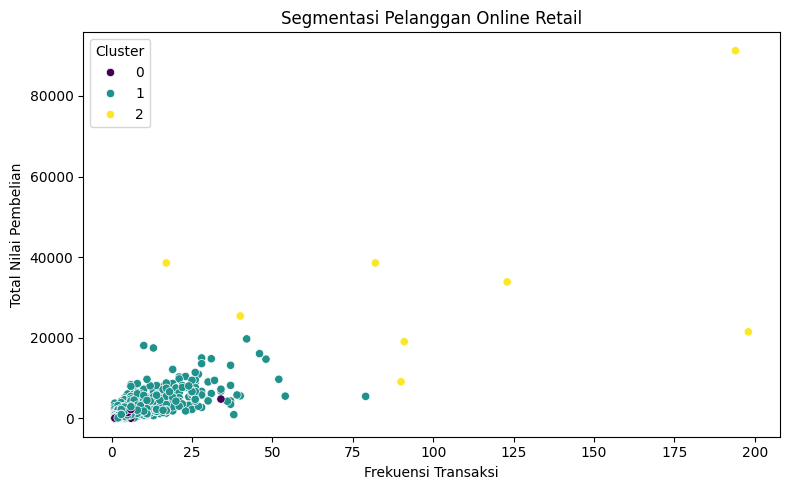

In [21]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis"
)

plt.title("Segmentasi Pelanggan Online Retail")
plt.xlabel("Frekuensi Transaksi")
plt.ylabel("Total Nilai Pembelian")
plt.tight_layout()
plt.show()


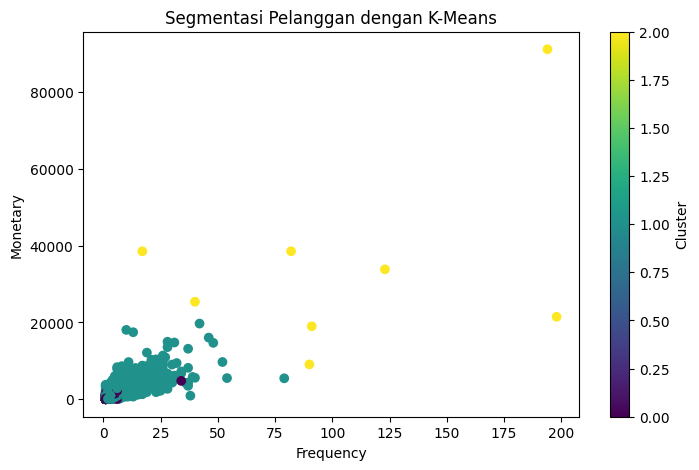

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(
    rfm["Frequency"],
    rfm["Monetary"],
    c=rfm["Cluster"],
    cmap="viridis"
)

plt.title("Segmentasi Pelanggan dengan K-Means")
plt.xlabel("Frequency")
plt.ylabel("Monetary")
plt.colorbar(label="Cluster")
plt.show()

In [1]:

import streamlit as st

# Judul aplikasi
st.title("🤖 MACHINE LEARNING")
st.header("Analisis Data Online Retail")
st.subheader("Implementasi Streamlit Bab 1 dan Bab 2")

st.write("Selamat datang di aplikasi analisis data Online Retail.")

st.markdown("""
Aplikasi ini dibuat untuk mempraktikkan
komponen Streamlit berdasarkan materi Bab 1 dan Bab 2.
""")


2026-11-11 13:38:57.399 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 13:38:58.239 
  command:

    streamlit run C:\Users\mrads\AppData\Roaming\Python\Python314\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-11 13:38:58.240 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 13:38:58.241 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 13:38:58.242 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 13:38:58.243 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 13:38:58.243 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-11 13:38:58.244 Thre

DeltaGenerator()

## 📊 Evaluasi

Berdasarkan proses pengolahan dataset Online Retail, data telah melalui beberapa tahap preprocessing, mulai dari pemeriksaan missing value, duplikat, data tidak konsisten, data tidak valid, outlier, format data, encoding, normalisasi, feature engineering, hingga seleksi fitur.

Hasil preprocessing menunjukkan bahwa data menjadi lebih terstruktur dan siap digunakan untuk proses analisis atau penerapan algoritma Machine Learning. Beberapa fitur numerik juga telah disesuaikan skalanya, sedangkan fitur baru `TotalPrice` berhasil dibuat untuk memberikan informasi tambahan mengenai nilai transaksi.


## 📝 Kesimpulan

Berdasarkan hasil pengolahan dataset Online Retail, proses preprocessing berhasil dilakukan melalui 10 tahapan permasalahan data. Setiap permasalahan ditangani menggunakan metode yang sesuai, seperti penghapusan data tidak valid, metode IQR untuk outlier, konversi format tanggal, Label Encoding, Min-Max Scaling, Feature Engineering, dan analisis korelasi.

Setelah seluruh tahapan selesai, dataset menjadi lebih bersih, terstruktur, dan memiliki fitur tambahan yang dapat digunakan untuk tahap analisis atau Machine Learning selanjutnya.
